# Trend Forecasting with an asymptote

### Guido Marzetti

Some time series exhibit a persistent trend toward a limit that the underlying process cannot cross. In such cases, modelling the distance to the limit captures how the scope for further change diminishes over time. In this brief work illustrate this idea using men’s winning times at the Boston Marathon, with an exponential trend that approaches an assumed lower asymptote.

This note grew out of my reading of Section 7.7 of *Forecasting: Principles and Practice* by Hyndman and Athanasopoulos. I revisit their Boston Marathon example to explore how we might forecast a trend when the underlying process has a limit it cannot cross. I model men’s winning times with an exponential trend that approaches an assumed lower bound, so that projected improvements become smaller as times approach that limit.

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘quadprog’, ‘progressr’, ‘ggdist’, ‘numDeriv’, ‘warp’, ‘BH’, ‘fabletools’, ‘distributional’, ‘slider’, ‘vecvec’, ‘mixtime’, ‘anytime’, ‘fable’, ‘feasts’, ‘ggtime’, ‘tsibble’, ‘tsibbledata’


── Attaching packages ──────────────────────────────────────────── fpp3 1.0.3 ──

✔ tibble      3.3.1     ✔ tsibble     1.2.0
✔ dplyr       1.2.1     ✔ tsibbledata 0.4.1
✔ tidyr       1.3.2     ✔ ggtime      1.1.1
✔ lubridate   1.9.5     ✔ feasts      0.5.0
✔ ggplot2     4.0.3     ✔ fable       0.5.0

── Conflicts ───────────────────────────────────────────────── fpp3_conflicts ──
✖ lubridate::date()    masks base::date()
✖ dplyr::filter()      masks stats::filter()
✖ tsibble::intersect() masks base::intersect()
✖ tsibble::interval()  masks lubridate::interval()
✖ dplyr::lag()         masks stats::lag()
✖ tsibble::setdiff()   masks base::setdiff()
✖ tsibble::union()     masks base::un

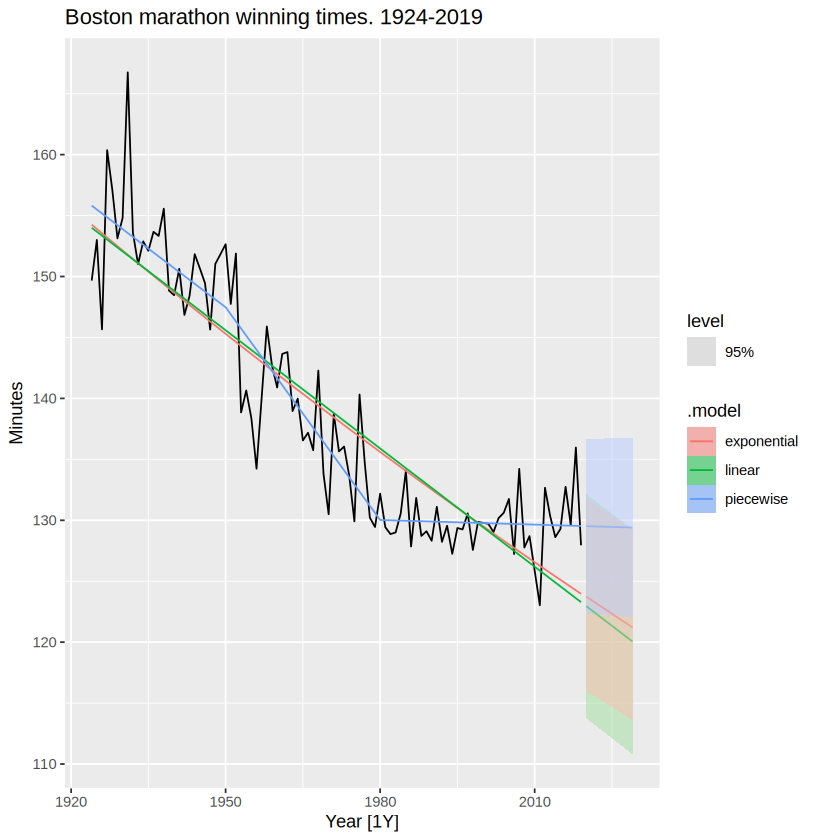

In [ ]:
#install.packages("fpp3")
library(fpp3)

boston_men <- boston_marathon |>
  filter(Year >= 1924,
         Event == "Men's open division") |>
  mutate(Minutes = as.numeric(Time) / 60)

fit_trends <- boston_men |>
  model(
    linear = TSLM(Minutes ~ trend()),
    exponential = TSLM(log(Minutes) ~ trend()),
    piecewise = TSLM(Minutes ~ trend(knots = c(1950, 1980)))
  )
fc_trends <- fit_trends |> forecast(h = 10)

boston_men |>
  autoplot(Minutes) +
  geom_line(data = fitted(fit_trends), aes(y = .fitted, colour = .model)) +
  autolayer(fc_trends, alpha = 0.5, level = 95) +
  labs(y = "Minutes", title = "Boston marathon winning times. 1924-2019")  #this is what we see in the textbook


## Thinking to the limit

In this case, I think that we can model the trend by exploiting a theoretical limit on human performance. Various studies set the limit for the marathon between 1h48'25" (Péronnet and Thibault, 1989) and 1h57'58" (Joyner, 1991). We use this limit as the asymptote $L$ of the trend.

An asymptotic trend can be written as

$$Y_t = L + e^{a + bt}, \qquad b < 0,$$

where $t$ is the time index (in years) and $a$, $b$ are parameters estimated from the data. As $t \to \infty$, $Y_t \to L$.

In [ ]:
fit_asymptotic_trends  <- boston_men |>
  model(
    linear = TSLM(Minutes ~ trend()),
    exponential = TSLM(log(Minutes) ~ trend()),
    piecewise = TSLM(Minutes ~ trend(knots = c(1950, 1980))),
    asympt_115 = TSLM(log(Minutes - 115) ~ trend()),
    asympt_116 = TSLM(log(Minutes - 116) ~ trend())
  )
fc_asymptotic_trends <- fit_asymptotic_trends |> forecast(h = 10)

In [ ]:
#new data
recent <- tibble(
  Year = 2021:2026,
  Time = c("2:09:51", "2:06:51", "2:05:54",
           "2:06:17", "2:04:45", "2:01:52")
) |>
  mutate(Minutes = as.numeric(lubridate::hms(Time)) / 60) |>
  select(Year, Minutes) |>
  as_tsibble(index = Year)

In [ ]:
fc_asymptotic_trends |>
  filter(Year %in% recent$Year) |>
  accuracy(recent) |>
  select(.model, RMSE, MAE, MAPE, ME) |>
  arrange(RMSE)

.model,RMSE,MAE,MAPE,ME
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
asympt_115,2.156794,1.574625,1.251716,0.09518792
asympt_116,2.163261,1.578411,1.256051,-0.02452031
exponential,3.711159,3.222207,2.532262,3.16075494
piecewise,4.274886,3.673012,2.951061,-3.55863239
linear,4.502291,4.090087,3.221146,4.09008749


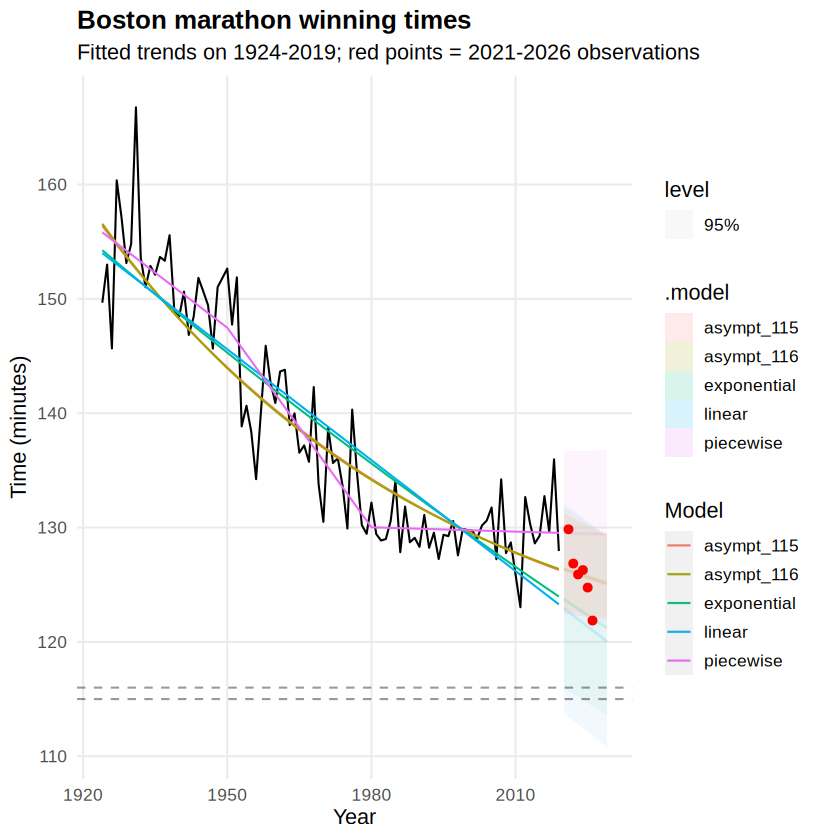

In [ ]:
boston_men |>
  autoplot(Minutes) +
  geom_line(data = fitted(fit_asymptotic_trends),
            aes(y = .fitted, colour = .model)) +
  autolayer(fc_asymptotic_trends, level = 95, alpha=0.15, linewidth = 0.8) +
  geom_point(data = recent, aes(y = Minutes),
             colour = "red", size = 2) +
  geom_hline(yintercept = c(115, 116), linetype = "dashed", alpha = 0.4) +
  labs(
    title = "Boston marathon winning times",
    subtitle = "Fitted trends on 1924-2019; red points = 2021-2026 observations",
    x = "Year", y = "Time (minutes)", colour = "Model"
  )+
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(face = "bold"),
    panel.grid.minor = element_blank(),
    plot.caption = element_text(colour = "grey40")
  )

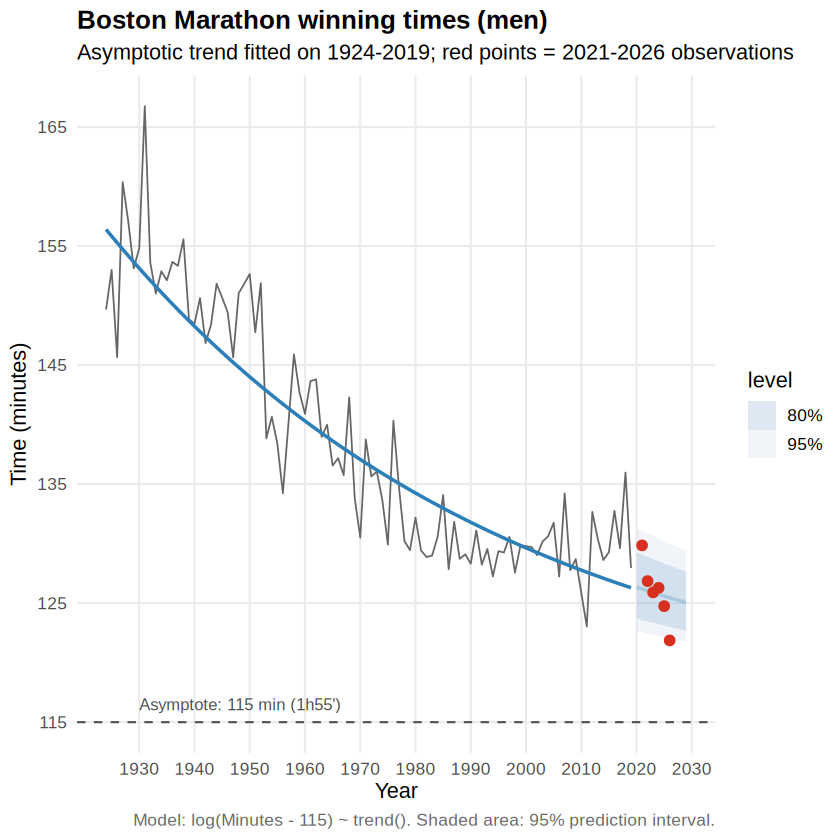

In [ ]:
fit_115 <- fit_asymptotic_trends |> select(asympt_115)
fc_115  <- fc_asymptotic_trends |> filter(.model == "asympt_115")

boston_men |>
  autoplot(Minutes, colour = "grey40", linewidth = 0.5) +
  geom_line(data = fitted(fit_115), aes(y = .fitted),
            colour = "#2C7FB8", linewidth = 1) +
  autolayer(fc_115, level = c(80, 95), colour = "#2C7FB8", fill = "#2C7FB8",
            alpha = 0.25, linewidth = 1) +
  geom_point(data = recent, aes(y = Minutes),
             colour = "#D7301F", size = 2.5) +
  geom_hline(yintercept = 115, linetype = "dashed", colour = "grey30") +
  annotate("text", x = 1930, y = 116.5, label = "Asymptote: 115 min (1h55')",
           hjust = 0, size = 3.5, colour = "grey30") +
  scale_x_continuous(breaks = seq(1930, 2030, by = 10)) +
  scale_y_continuous(breaks = seq(115, 175, by = 10)) +
  labs(
    title = "Boston Marathon winning times (men)",
    subtitle = "Asymptotic trend fitted on 1924-2019; red points = 2021-2026 observations",
    x = "Year", y = "Time (minutes)",
    caption = "Model: log(Minutes - 115) ~ trend(). Shaded area: 95% prediction interval."
  ) +
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(face = "bold"),
    panel.grid.minor = element_blank(),
    plot.caption = element_text(colour = "grey40")
  )